In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
import matplotlib.gridspec as gridspec
import metpy.calc as mpcalc
from metpy.cbook import get_test_data
from metpy.plots import Hodograph, SkewT
from metpy.units import units
import numpy as np
import csv
import os
from netCDF4 import Dataset

from wrf import (getvar, interplevel, vertcross, 
                 CoordPair, ALL_TIMES, to_np,ll_to_xy,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times)

/glade/work/fdemartin/conda-envs/jupyter/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
#folder="vortex_u35_coriolis"
folder="no_urban"
dir="/glade/u/home/fdemartin/plot/sounding"

In [6]:
latlon = pd.read_csv("/glade/u/home/fdemartin/dati/derecho/punti_"+folder+".csv", sep =',')
#print(latlon)
T2=latlon['T2_u'].values
Q2=latlon['Q2_u'].values
T2_r=latlon['T2_r'].values
Q2_r=latlon['Q2_r'].values
time=latlon['Unnamed: 0'].values

folder2="hb60"
latlon2 = pd.read_csv("/glade/u/home/fdemartin/dati/derecho/punti_"+folder2+".csv", sep =',')
#print(latlon)
T22=latlon2['T2_u'].values
Q22=latlon2['Q2_u'].values
T2_r2=latlon2['T2_r'].values
Q2_r2=latlon2['Q2_r'].values
time2=latlon2['Unnamed: 0'].values

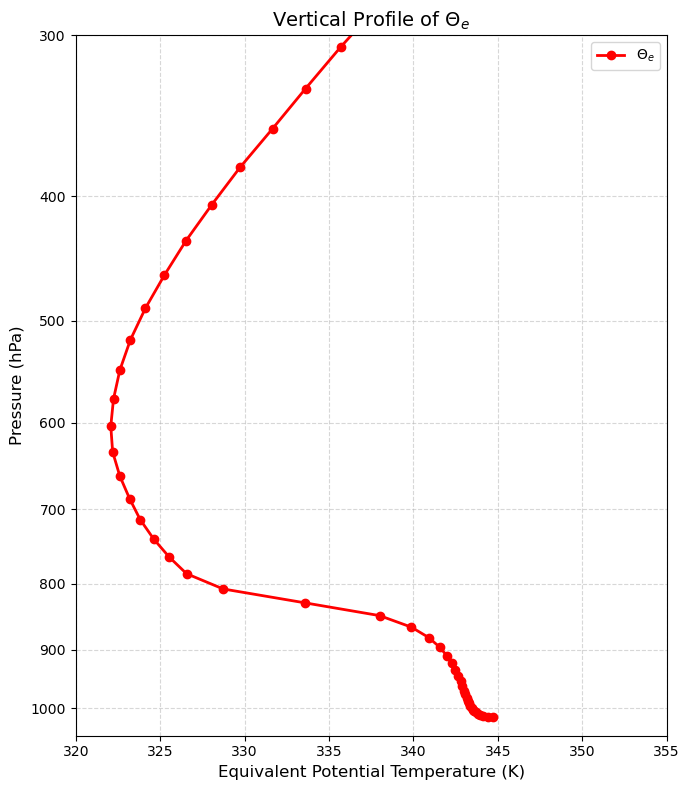

In [3]:
folder="no_urban"
latlon= pd.read_csv("/glade/u/home/fdemartin/dati/derecho/metpy_sounding_urban_1530_"+folder+".csv", sep =',')
#print(latlon)
z=latlon['z'].values
pressure=latlon['p'].values
tc=latlon['t'].values
td=latlon['td'].values
ua=latlon['ua'].values
va=latlon['va'].values

u=units.Quantity(ua,"m/s")
v=units.Quantity(va,"m/s")
hght=units.Quantity(z,"m")
t=units.Quantity(tc,"degC")
dp=units.Quantity(td,"degC")
p=units.Quantity(pressure,"Pa")

folder2="30km"
latlon_s = pd.read_csv("/glade/u/home/fdemartin/dati/derecho/metpy_sounding_urban_1530_"+folder2+".csv", sep =',')
#print(latlon)
z2=latlon_s['z'].values
pressure2=latlon_s['p'].values
tc2=latlon_s['t'].values
td2=latlon_s['td'].values
ua2=latlon_s['ua'].values
va2=latlon_s['va'].values

u2=units.Quantity(ua2,"m/s")
v2=units.Quantity(va2,"m/s")
hght2=units.Quantity(z2,"m")
t2=units.Quantity(tc2,"degC")
dp2=units.Quantity(td2,"degC")
p2=units.Quantity(pressure2,"Pa")

# 2. Calculate Equivalent Potential Temperature (Theta-e)
# MetPy uses the Bolton (1980) formulation by default
theta_e = mpcalc.equivalent_potential_temperature(p2, t2, dp2)

# 3. Create the Plot
fig, ax = plt.subplots(figsize=(7, 8))

ax.plot(theta_e, p2.to("hPa"), marker='o', color='red', linewidth=2, label='$\Theta_e$')

# Invert Y-axis because pressure decreases with height
ax.set_yscale('log')
ax.invert_yaxis()
ax.set_ylim([1050,300])
ax.set_xlim([320,355])
# Formatting for meteorological standards
ax.set_yticks([1000, 900, 800, 700, 600, 500, 400, 300])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())

ax.set_xlabel('Equivalent Potential Temperature (K)', fontsize=12)
ax.set_ylabel('Pressure (hPa)', fontsize=12)
ax.set_title('Vertical Profile of $\Theta_e$', fontsize=14)
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.legend()

plt.tight_layout()
plt.savefig(dir+"_theta_e.png")

In [4]:
#parcel_prof = mpcalc.parcel_profile(p, t[0], dp[0])
parcel_prof = mpcalc.mixed_parcel(p, t, dp)
parcel_prof = mpcalc.parcel_profile(p,parcel_prof[1],parcel_prof[2])
parcel_prof = mpcalc.parcel_profile(p, t[0], dp[0])
parcel_prof2 = mpcalc.parcel_profile(p2, t2[0], dp2[0])
cape, cinh = mpcalc.surface_based_cape_cin(p, t, dp)#, parcel_prof)
cape2, cinh2 = mpcalc.surface_based_cape_cin(p2, t2, dp2)#, parcel_prof2)
lclpres, lcltemp = mpcalc.lcl(p[0], t[0], dp[0])
lclpres2, lcltemp2 = mpcalc.lcl(p2[0], t2[0], dp2[0])
#calcolo grandezze legate al wind shear
u_shr,v_shr=mpcalc.bulk_shear(p, u, v,hght,depth=6000*units.m)
#u_shr1,v_shr1=mpcalc.bulk_shear(p, u, v,h,depth=1000*units.m)
shr=(u_shr**2+v_shr**2)**(1/2)
#shr1=(u_shr1**2+v_shr1**2)**(1/2)
right_mover, left_mover, wind_mean=mpcalc.bunkers_storm_motion(p, u, v, hght)
r_m=(right_mover[0]**2+right_mover[1]**2)**(1/2)
l_m=(left_mover[0]**2+left_mover[1]**2)**(1/2)
w_m=(wind_mean[0]**2+wind_mean[1]**2)**(1/2)
u_storm=right_mover[0]
v_storm=right_mover[1]
#crit_angle=mpcalc.critical_angle(p, u, v, h, u_storm, v_storm)

psrh, nsrh, tsrh = mpcalc.storm_relative_helicity(hght, u, v, 3000*units.m, bottom=0*units.m, storm_u=u_storm, storm_v=v_storm)
psrh1, nsrh1, tsrh1 = mpcalc.storm_relative_helicity(hght,u, v, 1000*units.m, bottom=0*units.m, storm_u=u_storm, storm_v=v_storm)
lclhght = np.interp(lclpres.m, p[::-1].m, hght[::-1])
lclhght2 = np.interp(lclpres2.m, p2[::-1].m, hght2[::-1])

right_mover2, left_mover2, wind_mean2=mpcalc.bunkers_storm_motion(p2, u2, v2, hght2)
r_m2=(right_mover2[0]**2+right_mover2[1]**2)**(1/2)
l_m2=(left_mover2[0]**2+left_mover2[1]**2)**(1/2)

u_storm2=right_mover2[0]
v_storm2=right_mover2[1]
#crit_angle=mpcalc.critical_angle(p, u, v, h, u_storm, v_storm)
psrh2, nsrh2, tsrh2 = mpcalc.storm_relative_helicity(hght2, u2, v2, 3000*units.m, bottom=0*units.m, storm_u=u_storm2, storm_v=v_storm2)

print('Sondaggio day')
print(cape.m,cinh.m,lclhght.m,tsrh.m,tsrh1.m,shr.m)
print('Sondaggio night')
print(cape2.m,cinh2.m,lclhght2.m,tsrh2.m)

Sondaggio day
2682.3471438988627 0 1084.1552411996045 206.10827192348398 32.98215872050344 31.7879842412089
Sondaggio night
1710.3989928928647 0 1597.8191697002483 178.66648065525686


/glade/u/home/fdemartin/plot/sounding no_urban


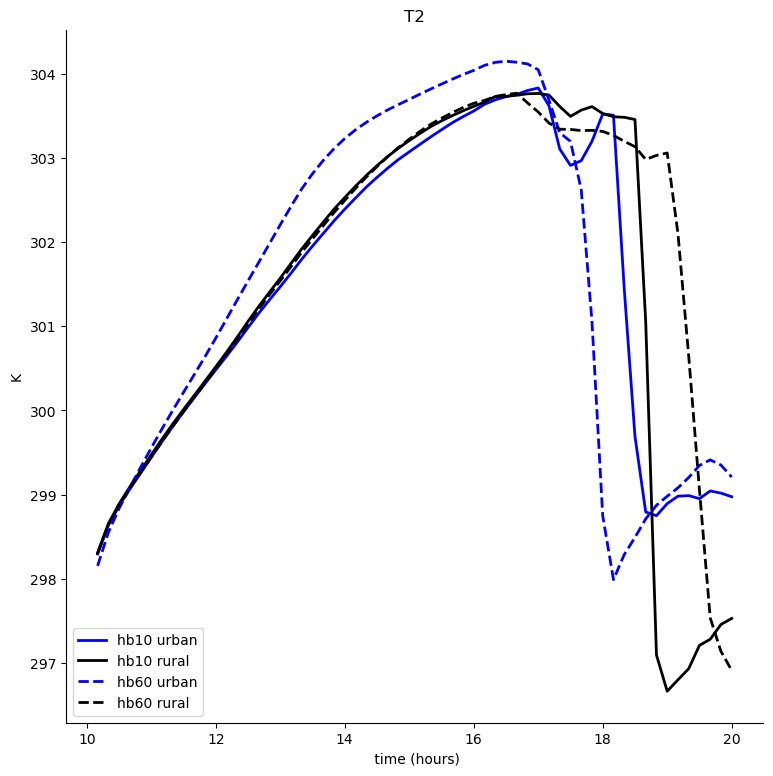

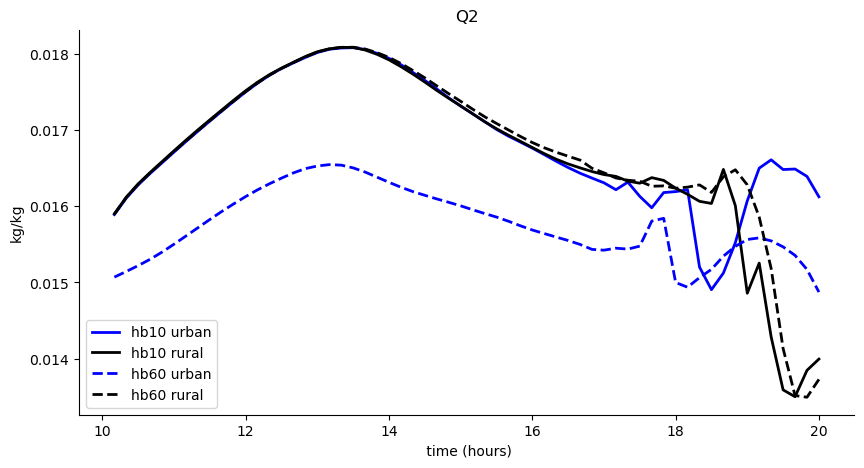

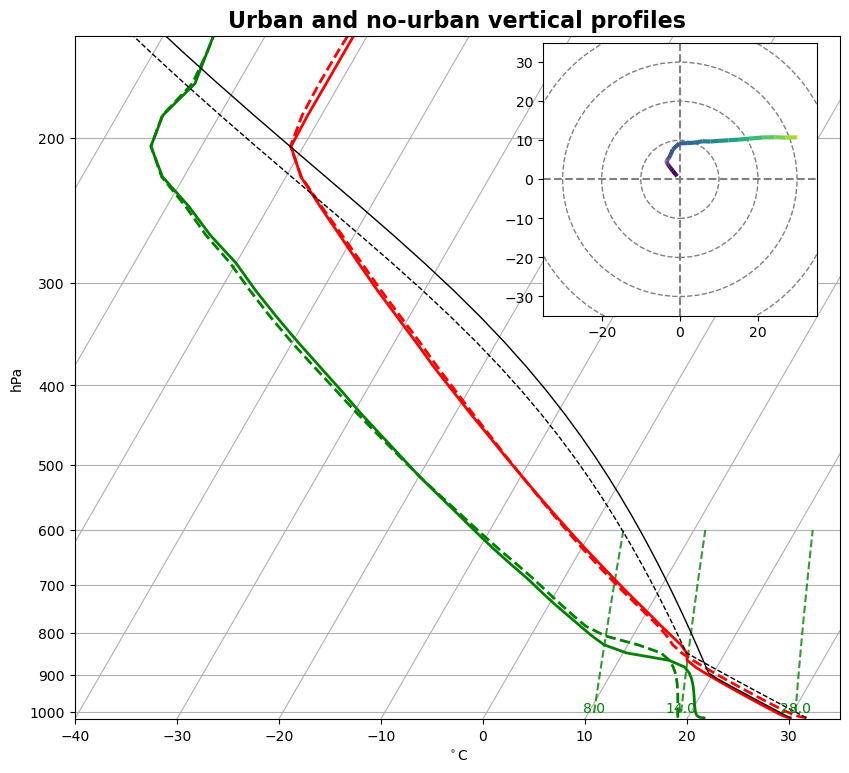

In [11]:
fig,ax1 = plt.subplots(figsize=[9,9],ncols=1,sharey=True)
plt.plot(time[1:],T2[1:], 'b-', linewidth=2,label='hb10 urban')
plt.plot(time[1:],T2_r[1:], 'k-', linewidth=2,label='hb10 rural')
ax1.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax1.spines['right'].set_visible(False)  # Rimuove il bordo destro
plt.plot(time2[1:],T22[1:], 'b--', linewidth=2,label='hb60 urban')
plt.plot(time2[1:],T2_r2[1:], 'k--', linewidth=2,label='hb60 rural')
# plt.plot(time3[1:],T23[1:], 'b--', linewidth=2,label='urban initialization 12 utc')
# plt.plot(time3[1:],T2_r3[1:], 'k--', linewidth=2,label='rural initialization 12 utc')

#ax1.plot(-np.array(data2["posizione"]),np.array(data2["z_lcl"]), 'b--', linewidth=2,label='LCL bm60')
plt.xlabel(' time (hours)')
plt.tick_params(axis='y')
ax1.set_ylabel('K')
#ax1.set_ylim(15*units.degC,25*units.degC)
#ax1.set_xlim((start_time+1/6)*units.hour,(start_time+delta_time*(period-1))*units.hour)
plt.title('T2')
#ax1.set_ylim(0,3500)
#plt.grid()
plt.legend(loc=3)
#plt.show()
file_name='T2_km5.png'
plt.savefig(dir + "_" + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)

fig,ax1 = plt.subplots(figsize=[10,5],ncols=1,sharey=True)
plt.plot(time[1:],Q2[1:], 'b-', linewidth=2,label='hb10 urban')
plt.plot(time[1:],Q2_r[1:], 'k-', linewidth=2,label='hb10 rural')
ax1.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax1.spines['right'].set_visible(False)  # Rimuove il bordo destro
plt.plot(time2[1:],Q22[1:], 'b--', linewidth=2,label='hb60 urban')
plt.plot(time2[1:],Q2_r2[1:], 'k--', linewidth=2,label='hb60 rural')
# plt.plot(time3[1:],Q23[1:], 'b--', linewidth=2,label='urban initialization 12 utc')
# plt.plot(time3[1:],Q2_r3[1:], 'k--', linewidth=2,label='rural initialization 12 utc')

#ax1.plot(-np.array(data2["posizione"]),np.array(data2["z_lcl"]), 'b--', linewidth=2,label='LCL bm60')
plt.xlabel(' time (hours)')
plt.tick_params(axis='y')
ax1.set_ylabel('kg/kg')
#ax1.set_ylim(15*units.degC,25*units.degC)
#ax1.set_xlim((start_time+1/6)*units.hour,(start_time+delta_time*(period-1))*units.hour)
plt.title('Q2')
#ax1.set_ylim(0,3500)
#plt.grid()
plt.legend(loc=3)
#plt.show()
file_name='Q2_km5.png'
plt.savefig(dir + "_" + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)

fig = plt.figure(figsize=(9, 9))
skew = SkewT(fig)

# Plot the data using normal plotting functions, in this case using
# log scaling in Y, as dictated by the typical meteorological plot
skew.plot(p, t, 'r', linewidth=2)
skew.plot(p, dp, 'g', linewidth=2)
skew.plot(p2, t2, 'r--', linewidth=2)
skew.plot(p2, dp2, 'g--', linewidth=2)

#skew.plot_barbs(p, u, v)
# Plot the parcel profile as a black line
skew.plot(p, parcel_prof, 'k-', linewidth=1)
skew.plot(p2, parcel_prof2, 'k--', linewidth=1)

w = np.array([0.028, 0.014, 0.008, 0.004, 0.002, 0.001,0.0005,0.0001])[:, None] * units('g/g')
w = np.array([0.028, 0.014, 0.008])[:, None] * units('g/g')
p_w = units.hPa * np.linspace(1000, 600, 6)
skew.plot_mixing_lines(w, p_w, colors='green')
for val in w.flatten()[::1]:
    top_p = p_w[0]
    dewpt = mpcalc.dewpoint(mpcalc.vapor_pressure(top_p, val))
    skew.ax.text(dewpt, top_p, str(val.to('g/kg').m),
                horizontalalignment='center',color='g')

# Shade areas of CAPE and CIN
#skew.shade_cape(p, t, parcel_prof)
#skew.shade_cape(p2, t2, parcel_prof2)

# Plot LCL temperature as black dot
#skew.plot(lcl_pressure, lcl_temperature, 'ko', markerfacecolor='purple')

# Plot a zero degree isotherm
#skew.ax.axvline(0, color='c', linestyle='--', linewidth=2)

skew.ax.set_ylim(1020, 150)
skew.ax.set_xlim(-40, 35)
skew.ax.set_xlabel("$^\circ$C")
skew.ax.set_ylabel("hPa")
skew.ax.set_title("Urban and no-urban vertical profiles", fontsize=16, fontweight='bold')
#Create a hodograph
#Create an inset axes object that is 40% width and height of the
#figure and put it in the upper right hand corner.

n=0
for j in range(0,len(p)):
    if p[j]>450*units.hPa:
        n=n+1

uh=np.zeros(n)*units("m/s")
vh=np.zeros(n)*units("m/s")
zh=np.zeros(n)*units("m")

for j in range(0,len(p)):
    if p[j]>450*units.hPa:

        uh[j]=u2[j]
        vh[j]=v2[j]
        zh[j]=hght2[j]

#i=np.sqrt(u**2+v**2)
ax_hod = inset_axes(skew.ax, '40%', '40%', loc=1)
h = Hodograph(ax_hod, component_range=35.)
h.add_grid(increment=10)
h.plot_colormapped(uh, vh, zh)  # Plot a line colored by wind speed
#plt.colorbar(h)

# Show the plot
#plt.show()
skew.ax.set_position([0.08, 0.08, 0.85, 0.85])  # [left, bottom, width, height] in frazioni di figura
plt.savefig(dir+folder+".png",dpi=300)#, dpi = 130, bbox_inches = 'tight', pad_inches = 0)  
print(dir,folder)